# Mature-age draftees: a hold-out test, then a closer look

Notebook 02 found that mature-age draftees (19.0+ on 30 November of their
draft year) beat their pick by about 19 more games than juniors over 8 seasons.
That was a secondary result, so this notebook does two things:

- **Part B, confirmatory:** a test on the **2019–2021 drafts**, which weren't
  used in any earlier analysis. It follows the
  [pre-registration](../docs/preregistration_mature_age_holdout.md), which was
  committed before those drafts were fetched. It comes first so it isn't shaped
  by the exploration.
- **Part A, exploratory:** five questions about *where* the effect comes from,
  using the 2005–2018 drafts. These weren't pre-registered, so they describe
  the data rather than test anything.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.analysis import bootstrap, expected_at_pick
from afl.datasets import draft_outcomes
from afl.draft_charts import BLUE, GREY, INK, ORANGE, TITLE, apply_style

N_BOOT = 2000
pd.set_option("display.width", 200)
apply_style()


def mature_minus_junior(data, col="resid_games"):
    return (data.loc[data["mature_age"], col].mean()
            - data.loc[~data["mature_age"], col].mean())


def fmt(result, unit=""):
    est, low, high = result
    return f"{est:+.1f}{unit}  [95% CI {low:+.1f} to {high:+.1f}]"


def dot_plot(ax, labels, results, colour=BLUE, unit=""):
    """Point estimates with 95% intervals, one per label, with a zero line."""
    x = np.arange(len(labels))
    est = np.array([r[0] for r in results])
    low = np.array([r[1] for r in results])
    high = np.array([r[2] for r in results])
    ax.errorbar(x, est, yerr=[est - low, high - est], fmt="o", color=colour,
                markersize=8, capsize=0, elinewidth=2)
    for xi, e, h in zip(x, est, high):
        ax.annotate(f"{e:+.0f}{unit}", (xi, h), xytext=(0, 6), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_xticks(x, labels)
    ax.set_xlim(-0.5, len(labels) - 0.5)
    ax.grid(axis="x", visible=False)

# Part B: hold-out test on the 2019–2021 drafts (pre-registered)

**H:** in the 2019–2021 national drafts, mature-age draftees beat their pick by
more than juniors do, over their first 5 seasons.

- **Baseline:** mean 5-season games of 2019–2021 picks within ±4, leaving the player's own result out.
- **Reading:** *supported* if the whole 95% interval is above 0.
- **Power:** expected power is about two-thirds, so an inconclusive result
  wouldn't count against the effect.

In [2]:
holdout = draft_outcomes(2019, 2021, windows=(5,))
print(holdout["match_status"].value_counts().to_string())
print(f"\nPicks 1-80: {len(holdout)}  |  missing date of birth: {holdout['age'].isna().sum()}")
print(f"Mature-age: {holdout['mature_age'].sum()}  |  juniors: {(~holdout['mature_age']).sum()}")
print(f"Bid-matched: {holdout['bid_matched'].sum()}  |  recycled: {(holdout['prior_games'] > 0).sum()}")

match_status
name            169
never played     18
manual            2

Picks 1-80: 189  |  missing date of birth: 0
Mature-age: 16  |  juniors: 173
Bid-matched: 27  |  recycled: 1


In [3]:
def add_holdout_residuals(data, window=4, leave_one_out=True):
    data = data.copy()
    data["games"] = data["games_5"]
    data["bust"] = (data["games"] < 50).astype(float)
    data["massive_bust"] = (data["games"] < 20).astype(float)
    for col in ["games", "bust", "massive_bust"]:
        data[f"expected_{col}"] = expected_at_pick(data, col, window=window, leave_one_out=leave_one_out)
        data[f"resid_{col}"] = data[col] - data[f"expected_{col}"]
    return data


hb = add_holdout_residuals(holdout)
h = bootstrap(hb, mature_minus_junior, n=N_BOOT)

if h[1] > 0:
    reading = "SUPPORTED (interval above 0)"
elif h[2] < 0:
    reading = "CONTRADICTED (interval below 0)"
else:
    reading = "INCONCLUSIVE (interval includes 0)"

print(f"H: mature-age minus junior, residual games over 5 seasons: {fmt(h, ' games')}")
print(f"   Pre-registered reading: {reading}")
print(f"\n   Mature-age mean residual: {hb.loc[hb['mature_age'], 'resid_games'].mean():+.1f} "
      f"(n={hb['mature_age'].sum()})")
print(f"   Junior mean residual:     {hb.loc[~hb['mature_age'], 'resid_games'].mean():+.1f} "
      f"(n={(~hb['mature_age']).sum()})")

H: mature-age minus junior, residual games over 5 seasons: +7.6 games  [95% CI -6.7 to +24.4]
   Pre-registered reading: INCONCLUSIVE (interval includes 0)

   Mature-age mean residual: +6.8 (n=16)
   Junior mean residual:     -0.8 (n=173)


### Part B secondary results (reported, not used to judge H)

In [4]:
secondary = {
    "Original baseline (±2, not leave-one-out)": add_holdout_residuals(holdout, window=2, leave_one_out=False),
    "Excl. bid-matched picks": add_holdout_residuals(holdout[~holdout["bid_matched"]]),
    "Excl. recycled players": add_holdout_residuals(holdout[holdout["prior_games"] == 0]),
}
for name, data in secondary.items():
    print(f"{name:42} {fmt(bootstrap(data, mature_minus_junior, n=N_BOOT), ' games')}")

print()
for col, label in [("bust", "Bust (<50 games)"), ("massive_bust", "Massive bust (<20 games)")]:
    for group, is_mature in [("mature-age", True), ("junior", False)]:
        g = hb[hb["mature_age"] == is_mature]
        print(f"{label:25} {group:10}: actual {g[col].mean():.0%}  expected at their picks {g[f'expected_{col}'].mean():.0%}")

Original baseline (±2, not leave-one-out)  +4.6 games  [95% CI -8.1 to +19.1]


Excl. bid-matched picks                    +8.3 games  [95% CI -7.5 to +26.7]


Excl. recycled players                     +9.3 games  [95% CI -5.7 to +26.8]

Bust (<50 games)          mature-age: actual 75%  expected at their picks 81%
Bust (<50 games)          junior    : actual 60%  expected at their picks 60%
Massive bust (<20 games)  mature-age: actual 31%  expected at their picks 43%
Massive bust (<20 games)  junior    : actual 29%  expected at their picks 27%


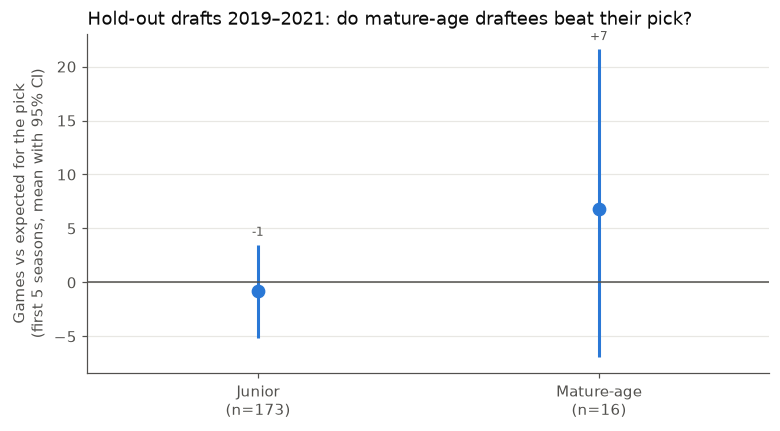

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
groups = [("Junior", hb[~hb["mature_age"]]), ("Mature-age", hb[hb["mature_age"]])]
results = [bootstrap(g, lambda d: d["resid_games"].mean(), n=N_BOOT) for _, g in groups]
dot_plot(ax, [f"{name}\n(n={len(g)})" for name, g in groups], results)
ax.set_ylabel("Games vs expected for the pick\n(first 5 seasons, mean with 95% CI)")
ax.set_title("Hold-out drafts 2019–2021: do mature-age draftees beat their pick?",
             loc="left", color=TITLE)
plt.show()

# Part A: where does the effect come from? (exploratory, 2005–2018)

These use notebook 02's set-up: games in the first 8 seasons, compared with the
mean for picks within ±2. Nothing here was pre-registered. Treat the intervals
as a sense of uncertainty, not as tests.

In [6]:
data = draft_outcomes(2005, 2018, windows=(8,))
data = data[data["age"].notna()].copy()

OUTCOMES = {
    "massive_bust": ("Massive bust (<20)", lambda g: g < 20),
    "bust": ("Bust (<50)", lambda g: g < 50),
    "hundred": ("100+ games", lambda g: g >= 100),
    "star": ("150+ games", lambda g: g >= 150),
}

data["games"] = data["games_8"]
for col, (_, rule) in OUTCOMES.items():
    data[col] = rule(data["games"]).astype(float)
for col in ["games", *OUTCOMES]:
    data[f"expected_{col}"] = expected_at_pick(data, col)
    data[f"resid_{col}"] = data[col] - data[f"expected_{col}"]

mature = data[data["mature_age"]]
junior = data[~data["mature_age"]]
print(f"2005-2018, picks 1-80: {len(data)} with a date of birth  |  mature-age {len(mature)}  |  junior {len(junior)}")
print(f"Mature-age average pick: {mature['pick'].mean():.1f}  |  junior average pick: {junior['pick'].mean():.1f}")

2005-2018, picks 1-80: 1003 with a date of birth  |  mature-age 155  |  junior 848
Mature-age average pick: 51.9  |  junior average pick: 34.1


## Q1. Floor or ceiling?

Do mature-age draftees beat their pick by busting less, by becoming stars more
often, or both? Each rate is compared with the typical rate at the same picks.
Results are in percentage points: below 0 for busts is good, above 0 for
100+ and 150+ is good.

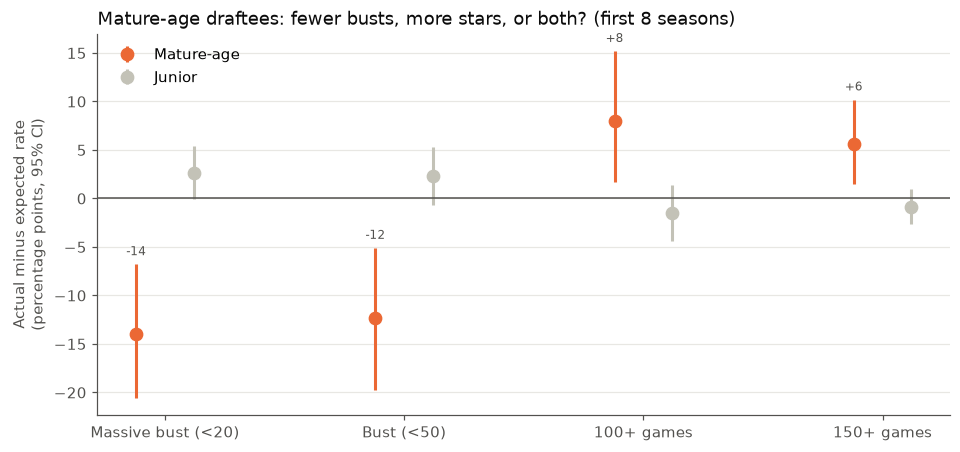

,outcome,group,actual,expected,difference (pts),low,high
0,Massive bust (<20),Mature-age,32%,46%,-13.9,-20.5,-6.8
1,Massive bust (<20),Junior,32%,30%,2.6,-0.1,5.4
2,Bust (<50),Mature-age,50%,63%,-12.3,-19.7,-5.1
3,Bust (<50),Junior,48%,46%,2.3,-0.7,5.3
4,100+ games,Mature-age,30%,22%,8.0,1.7,15.2
5,100+ games,Junior,34%,35%,-1.5,-4.4,1.4
6,150+ games,Mature-age,10%,4%,5.6,1.5,10.2
7,150+ games,Junior,9%,10%,-0.9,-2.7,0.9


In [7]:
rows = []
for col, (label, _) in OUTCOMES.items():
    for group, g in [("Mature-age", mature), ("Junior", junior)]:
        est, low, high = bootstrap(g, lambda d: d[f"resid_{col}"].mean() * 100, n=N_BOOT)
        rows.append({"outcome": label, "group": group, "actual": g[col].mean(),
                     "expected": g[f"expected_{col}"].mean(),
                     "difference (pts)": est, "low": low, "high": high})
q1 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [label for label, _ in OUTCOMES.values()]
x = np.arange(len(labels))
for offset, (group, colour) in zip([-0.12, 0.12], [("Mature-age", ORANGE), ("Junior", GREY)]):
    part = q1[q1["group"] == group]
    ax.errorbar(x + offset, part["difference (pts)"],
                yerr=[part["difference (pts)"] - part["low"], part["high"] - part["difference (pts)"]],
                fmt="o", color=colour, markersize=8, capsize=0, elinewidth=2, label=group)
for row in q1[q1["group"] == "Mature-age"].itertuples():
    xi = labels.index(row.outcome) - 0.12
    ax.annotate(f"{row._5:+.0f}", (xi, row.high), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
ax.axhline(0, color=INK, linewidth=1)
ax.set_xticks(x, labels)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Actual minus expected rate\n(percentage points, 95% CI)")
ax.set_title("Mature-age draftees: fewer busts, more stars, or both? (first 8 seasons)",
             loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper left")
plt.show()

q1.assign(actual=q1["actual"].map("{:.0%}".format), expected=q1["expected"].map("{:.0%}".format)).round(1)

### The late bloomers: mature-age draftees who reached 150+ games in 8 seasons

In [8]:
stars = mature[mature["games"] >= 150].sort_values("games", ascending=False)
print(f"{len(stars)} of {len(mature)} mature-age draftees reached 150+ games in 8 seasons")
stars[["draft_year", "pick", "player", "club", "age", "games", "expected_games"]].round(1)

15 of 155 mature-age draftees reached 150+ games in 8 seasons


,draft_year,pick,player,club,age,games,expected_games
383,2010,19,Isaac Smith,Hawthorn,21.9,181.0,83.3
161,2007,17,Harry Taylor,Geelong,21.5,180.0,91.4
834,2016,40,Tom Stewart,Geelong,23.7,171.0,54.1
902,2017,31,Bayley Fritsch,Melbourne,21.0,171.0,72.6
428,2010,66,Paul Puopolo,Hawthorn,23.0,168.0,36.8
895,2017,24,Tim Kelly,Geelong,23.3,164.0,78.6
397,2010,33,Jeremy Howe,Melbourne,20.4,162.0,56.4
54,2005,56,Joel Patfull,Brisbane,21.0,161.0,46.6
181,2007,37,Scott Thompson,North Melbourne,21.6,160.0,48.8
135,2006,71,Justin Westhoff,Port Adelaide,20.2,159.0,30.7


## Q2. What is the edge worth in pick terms?

For mature-age draftees in each pick range, I find the pick at which a
**junior** would be expected to play as many games. That's the "equivalent
junior pick".

The junior curve uses picks within ±5 (it needs to be smoother for this) and is
made non-increasing with a running minimum. That way each games total maps to a
single pick.

In [9]:
JUNIOR_WINDOW = 5
junior_curve = pd.Series(
    {p: junior.loc[(junior["pick"] - p).abs() <= JUNIOR_WINDOW, "games"].mean() for p in range(1, 81)}
).cummin()  # running minimum: the curve never goes back up


def equivalent_pick(mean_games):
    """First pick at which the junior curve drops to mean_games or below."""
    below = junior_curve[junior_curve <= mean_games]
    return below.index[0] if len(below) else 80


rows = []
for label, lo, hi in [("Picks 1–40", 1, 40), ("Picks 41–60", 41, 60), ("Picks 61–80", 61, 80), ("All picks 1–80", 1, 80)]:
    g = mature[mature["pick"].between(lo, hi)]
    est, low, high = bootstrap(g, lambda d: equivalent_pick(d["games"].mean()), n=N_BOOT)
    rows.append({"mature-age picks": label, "n": len(g), "average pick": g["pick"].mean(),
                 "mature-age games": g["games"].mean(),
                 "junior games at that pick": junior_curve[round(g["pick"].mean())],
                 "equivalent junior pick": est, "CI low": low, "CI high": high})
q2 = pd.DataFrame(rows).set_index("mature-age picks")
q2.round(1)

,n,average pick,mature-age games,junior games at that pick,equivalent junior pick,CI low,CI high
mature-age picks,,,,,,,
Picks 1–40,43,29.0,92.8,71.9,15,7.0,27.0
Picks 41–60,52,51.3,60.2,41.4,33,28.0,46.0
Picks 61–80,60,68.8,44.9,19.2,47,34.0,59.0
All picks 1–80,155,51.9,63.3,41.1,32,29.0,35.0


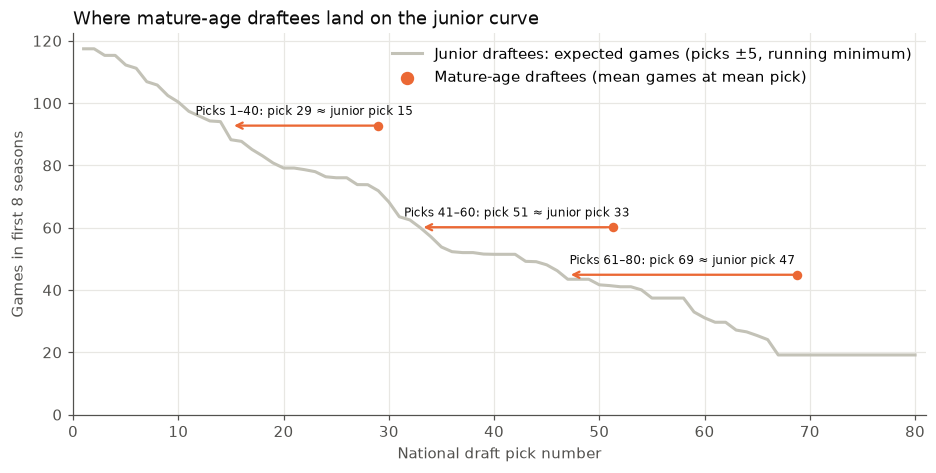

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(junior_curve.index, junior_curve.values, color=GREY, linewidth=2,
        label="Junior draftees: expected games (picks ±5, running minimum)")
for label, row in q2.drop(index="All picks 1–80").iterrows():
    ax.scatter(row["average pick"], row["mature-age games"], s=60, color=ORANGE, zorder=3,
               edgecolors="white", linewidths=1.5)
    ax.annotate("", xy=(row["equivalent junior pick"], row["mature-age games"]),
                xytext=(row["average pick"], row["mature-age games"]),
                arrowprops=dict(arrowstyle="->", color=ORANGE, linewidth=1.5))
    middle = (row["average pick"] + row["equivalent junior pick"]) / 2
    ax.annotate(f"{label}: pick {row['average pick']:.0f} ≈ junior pick "
                f"{row['equivalent junior pick']:.0f}",
                (middle, row["mature-age games"]), xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=8, color=TITLE)
ax.scatter([], [], s=60, color=ORANGE, label="Mature-age draftees (mean games at mean pick)")
ax.set_xlim(0, 81)
ax.set_ylim(bottom=0)
ax.set_xlabel("National draft pick number")
ax.set_ylabel("Games in first 8 seasons")
ax.set_title("Where mature-age draftees land on the junior curve", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper right")
plt.show()

## Q3. Does age within the mature-age group matter?

Is a 19-year-old who was passed over last year different from a 23-year-old
from the state leagues?

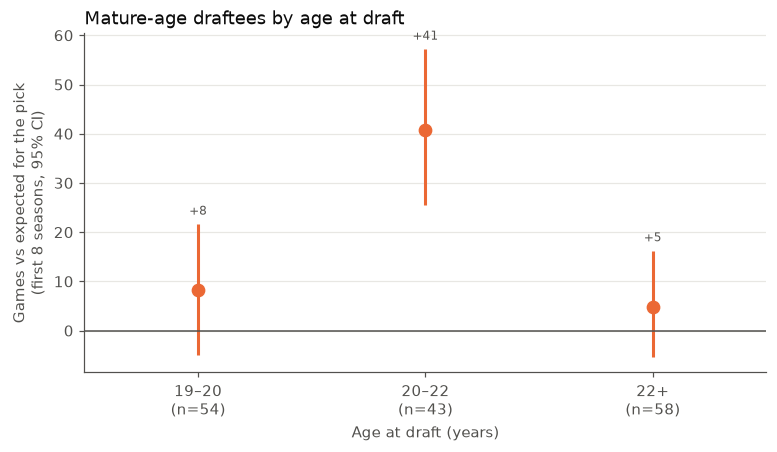

,n,average pick,games,expected,residual,low,high,bust rate,expected bust rate,recycled
age band,,,,,,,,,,
19–20,54,46.00,60.87,52.61,8.26,-4.89,21.69,0.48,0.58,1
20–22,43,50.02,89.91,49.17,40.74,25.54,57.25,0.35,0.61,5
22+,58,58.76,45.83,41.10,4.73,-5.33,16.27,0.64,0.68,16


In [11]:
AGE_BANDS = [19.0, 20.0, 22.0, 100]
AGE_LABELS = ["19–20", "20–22", "22+"]
banded = mature.assign(band=pd.cut(mature["age"], AGE_BANDS, right=False, labels=AGE_LABELS))

rows, results = [], []
for label in AGE_LABELS:
    g = banded[banded["band"] == label]
    res = bootstrap(g, lambda d: d["resid_games"].mean(), n=N_BOOT)
    results.append(res)
    rows.append({"age band": label, "n": len(g), "average pick": g["pick"].mean(),
                 "games": g["games"].mean(), "expected": g["expected_games"].mean(),
                 "residual": res[0], "low": res[1], "high": res[2], "bust rate": g["bust"].mean(),
                 "expected bust rate": g["expected_bust"].mean(),
                 "recycled": (g["prior_games"] > 0).sum()})

fig, ax = plt.subplots(figsize=(8, 4))
dot_plot(ax, [f"{label}\n(n={r['n']})" for label, r in zip(AGE_LABELS, rows)], results, colour=ORANGE)
ax.set_xlabel("Age at draft (years)")
ax.set_ylabel("Games vs expected for the pick\n(first 8 seasons, 95% CI)")
ax.set_title("Mature-age draftees by age at draft", loc="left", color=TITLE)
plt.show()
pd.DataFrame(rows).set_index("age band").round(2)

## Q4. Only at late picks?

Mature-age draftees average a much later pick than juniors. Do the few taken
early also beat their slot?

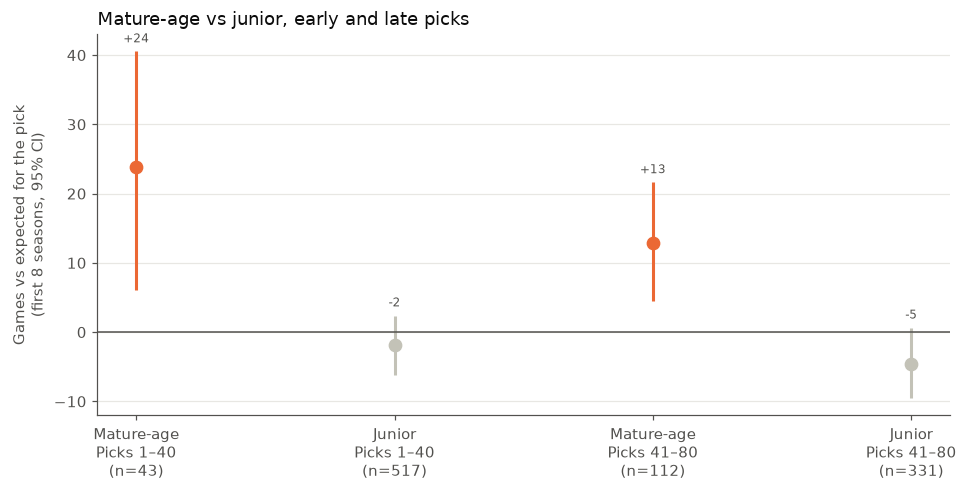

,pick range,group,n,residual,low,high
0,Picks 1–40,Mature-age,43,23.8,6.1,40.5
1,Picks 1–40,Junior,517,-1.9,-6.2,2.4
2,Picks 41–80,Mature-age,112,12.9,4.5,21.6
3,Picks 41–80,Junior,331,-4.6,-9.5,0.6


In [12]:
rows, results, labels = [], [], []
for range_label, lo, hi in [("Picks 1–40", 1, 40), ("Picks 41–80", 41, 80)]:
    for group, g in [("Mature-age", mature), ("Junior", junior)]:
        part = g[g["pick"].between(lo, hi)]
        res = bootstrap(part, lambda d: d["resid_games"].mean(), n=N_BOOT)
        results.append(res)
        labels.append(f"{group}\n{range_label}\n(n={len(part)})")
        rows.append({"pick range": range_label, "group": group, "n": len(part),
                     "residual": res[0], "low": res[1], "high": res[2]})

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(labels))
est = np.array([r[0] for r in results])
low = np.array([r[1] for r in results])
high = np.array([r[2] for r in results])
colours = [ORANGE if "Mature" in label else GREY for label in labels]
for xi, e, lo_, hi_, c in zip(x, est, low, high, colours):
    ax.errorbar(xi, e, yerr=[[e - lo_], [hi_ - e]], fmt="o", color=c, markersize=8,
                capsize=0, elinewidth=2)
    ax.annotate(f"{e:+.0f}", (xi, hi_), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
ax.axhline(0, color=INK, linewidth=1)
ax.set_xticks(x, labels)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Games vs expected for the pick\n(first 8 seasons, 95% CI)")
ax.set_title("Mature-age vs junior, early and late picks", loc="left", color=TITLE)
plt.show()
pd.DataFrame(rows).round(1)

## Q5. Has the market caught up?

If clubs learned that mature-age draftees beat their pick, we'd expect two
things: more of them drafted, and a smaller edge.

**Note:** the power check for Part B (on 2005–2018 data) had already shown the
edge was smaller for drafts around 2011–2015. This question was planned before
that check, but the pattern was seen first.

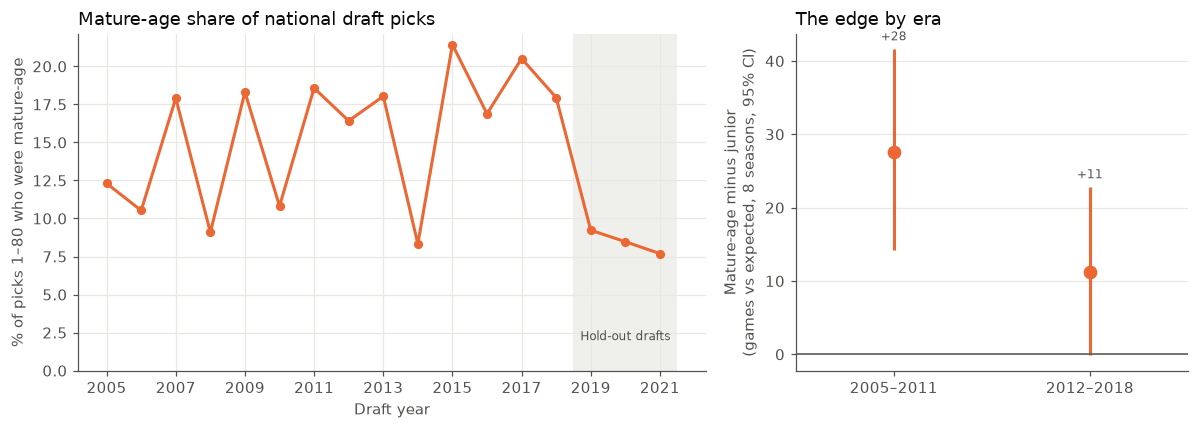

,era,mature-age picks,mature share,mature minus junior (games),low,high
0,2005–2011,69,0.14,27.63,14.16,41.57
1,2012–2018,86,0.17,11.25,-0.14,22.76


In [13]:
by_year = data.groupby("draft_year").agg(
    picks=("pick", "size"),
    mature_picks=("mature_age", "sum"),
)
by_year["mature_share"] = by_year["mature_picks"] / by_year["picks"]

# Add the hold-out drafts for the share trend (shares need no outcome window)
holdout_share = holdout.groupby("draft_year")["mature_age"].agg(["size", "sum"])
holdout_share = holdout_share.rename(columns={"size": "picks", "sum": "mature_picks"})
holdout_share["mature_share"] = holdout_share["mature_picks"] / holdout_share["picks"]
share = pd.concat([by_year, holdout_share])

ERAS = [("2005–2011", 2005, 2011), ("2012–2018", 2012, 2018)]
era_rows, era_results = [], []
for label, lo, hi in ERAS:
    part = data[data["draft_year"].between(lo, hi)]
    res = bootstrap(part, mature_minus_junior, n=N_BOOT)
    era_results.append(res)
    era_rows.append({"era": label, "mature-age picks": int(part["mature_age"].sum()),
                     "mature share": part["mature_age"].mean(),
                     "mature minus junior (games)": res[0], "low": res[1], "high": res[2]})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(share.index, share["mature_share"] * 100, color=ORANGE, linewidth=2, marker="o", markersize=5)
axes[0].axvspan(2018.5, 2021.5, color=GREY, alpha=0.25, linewidth=0)
axes[0].annotate("Hold-out drafts", (2020, 2), ha="center", fontsize=8, color=INK)
axes[0].set_ylim(bottom=0)
axes[0].set_xticks(range(2005, 2022, 2))
axes[0].set_xlabel("Draft year")
axes[0].set_ylabel("% of picks 1–80 who were mature-age")
axes[0].set_title("Mature-age share of national draft picks", loc="left", color=TITLE)
dot_plot(axes[1], [r["era"] for r in era_rows], era_results, colour=ORANGE)
axes[1].set_ylabel("Mature-age minus junior\n(games vs expected, 8 seasons, 95% CI)")
axes[1].set_title("The edge by era", loc="left", color=TITLE)
plt.tight_layout()
plt.show()

pd.DataFrame(era_rows).round(2)

### Where mature-age players are recruited from

The national draft isn't the only way in. This table uses the cached DraftGuru
year pages (their whole-year "Age" column, so 19+ only approximates the
definition above) to count players aged 19+ in every recruitment route.
"Post-Draft" covers signings after the drafts (e.g. delisted or uncontracted
players). It only appears from 2015.

In [14]:
from io import StringIO

from afl.fetch import fetch

routes = []
for year in range(2005, 2022):
    page = pd.read_html(StringIO(fetch(f"https://www.draftguru.com.au/years/{year}")))[0]
    page["age_years"] = pd.to_numeric(page["Age"].astype(str).str.replace("yr", ""), errors="coerce")
    page["draft_year"] = year
    routes.append(page[["draft_year", "Draft", "age_years"]])
routes = pd.concat(routes)
routes = routes[routes["Draft"].isin(["National", "Rookie", "Pre-Season", "Mid-Season", "Post-Draft"])]
routes["era"] = pd.cut(routes["draft_year"], [2004, 2011, 2018, 2021], labels=["2005–11", "2012–18", "2019–21"])
years_in_era = routes.groupby("era", observed=True)["draft_year"].nunique()

aged = routes[routes["age_years"] >= 19]
per_year = (aged.groupby(["era", "Draft"], observed=True).size().unstack(fill_value=0)
            .div(years_in_era, axis=0))
per_year["All routes"] = per_year.sum(axis=1)
print("Players aged 19+ recruited per year, by route")
per_year.round(1)

Players aged 19+ recruited per year, by route


Draft,Mid-Season,National,Post-Draft,Pre-Season,Rookie,All routes
era,,,,,,
2005–11,0.0,11.1,0.0,5.3,26.1,42.6
2012–18,1.6,12.1,4.6,0.9,22.1,41.3
2019–21,10.7,5.3,12.0,1.0,6.0,35.0


# Results

## Part B: hold-out test (pre-registered)

**Inconclusive.** In the 2019–2021 drafts, mature-age draftees beat their pick by
**7.6 more games than juniors over 5 seasons (95% CI −6.7 to +24.4)**. The
direction matches 2005–2018, but the interval includes 0. All three secondary
versions point the same way (+4.6 to +9.3), and none excludes 0.

**Why the test was weaker than planned.** The power estimate assumed about 33
mature-age draftees, the 2005–2018 rate. Only **16** were drafted at picks 1–80
in 2019–2021. The mature-age share of national draft picks halved, from 15–20%
to about 8%. As the pre-registration says, an inconclusive result is not
evidence against the effect. This test neither confirms nor refutes it.

The bust rates point the same way as in 2005–2018. Mature-age draftees had 31%
massive busts against 43% expected at their picks, while juniors were on
expectation (29% vs 27%).

## Part A: where the effect comes from (exploratory, 2005–2018)

**Q1. Floor and ceiling.** Compared with the typical outcome at their picks,
mature-age draftees:
- busted less: under 20 games 32% vs 46% expected (−14 pts); under 50 games 50% vs 63% (−12 pts)
- also became regular and star players more often: 100+ games 30% vs 22% (+8 pts); **150+ games 10% vs 4% (+6 pts)**
- Juniors were close to expectation on every measure.

So the idea that they "rarely bust but seldom become stars" is only half right.
At the picks where they're taken, they bust less *and* reach 150+ games more
often. **Caveat:** the 8-season window covers mature-age players' peak years
(roughly 20–29), but juniors' development years (18–26). Some juniors' best
seasons come after year 8, so this flatters the mature-age ceiling. A longer
window would be the right check.

**The late bloomers:** 15 of 155 mature-age draftees reached 150+ games in 8
seasons. They include Isaac Smith (pick 19, aged 21.9), Harry Taylor (17, 21.5),
Tom Stewart (40, 23.7), Bayley Fritsch (31, 21.0), Paul Puopolo (66, 23.0) and
Tim Kelly (24, 23.3).

**Q2. Worth about 20 pick places.** Mature-age draftees taken at an average pick of
52 played like a junior taken at **pick 32 (95% CI 29–35)**. It's similar at every
range: pick 29 ≈ junior pick 15, pick 51 ≈ 33, pick 69 ≈ 47.

**Q3. The edge is concentrated in 20–22-year-olds.** Players aged 20–22 at the
draft beat their pick by **+40.7 games (CI +25.5 to +57.3)** and busted 35% of
the time against 61% expected. Those aged 19–20 (+8.3, CI −4.9 to +21.7) and 22+
(+4.7, CI −5.3 to +16.3) were close to expectation. The 22+ group includes 16 of
the 23 recycled players. The bands were chosen before seeing results, but this
is still exploratory slicing of 155 players.

**Q4. Not only a late-pick effect.** Mature-age draftees beat their slot at picks
1–40 (+23.8, CI +6.1 to +40.5, n=43) and at picks 41–80 (+12.9, CI +4.5 to
+21.6, n=112). Juniors were slightly below expectation in both ranges.

**Q5. Some sign the market adjusted, then the route changed.**
- The edge was larger for the 2005–2011 drafts (+27.6, CI +14.2 to +41.6) than
  for 2012–2018 (+11.3, CI −0.1 to +22.8). Meanwhile the national-draft share of
  mature-age picks rose slightly (14% to 17%). That fits clubs partly catching on,
  but the intervals overlap. The dip was first seen during the Part B power check.
- From 2019 the **national draft stopped being the main route** for mature-age
  players. Across all routes, recruits aged 19+ held roughly steady (about 43,
  41 and 35 a year across the three eras). But the **mid-season draft** (from
  2019) and **post-draft signings** now take about 23 a year, while the national
  draft takes about 5.

## What this adds up to

- The 2005–2018 pattern is strong and consistent. Mature-age national draftees
  beat their pick by about 20 places' worth of games, through both fewer busts
  and more long careers, with 20–22-year-olds standing out.
- The hold-out test couldn't confirm it, mainly because of sample size. And the
  national draft is no longer where most mature-age players are recruited, so
  the national draft alone is becoming a weak place to study them.
- These are associations at the same pick, not causes. Mature-age players have
  years of senior state-league evidence behind them, which is exactly the
  "after college" information advantage. They may also be a different *type* of
  player, not just an older one.

## Possible next steps

1. Study mature-age players **across all routes**: mid-season draft, rookie
   lists and post-draft signings. This needs its own baseline, because a
   mid-season pick number doesn't mean the same as a national one.
2. Re-run the hold-out test when the 2022–2023 drafts reach 5 seasons (after
   2027 and 2028), pooled with 2019–2021.
3. Check the ceiling with a longer window (10+ seasons, 2005–2016 drafts) and
   with a quality measure, not just games.
4. Pre-register the 20–22 age band as a hypothesis for that future hold-out data.